## Imports, paths, functions

In [1]:
import numpy as np
import pandas as pd
import os, shutil
from tqdm import tqdm
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

In [2]:
%matplotlib inline

In [3]:
meta_input_dir = "/home-local2/sasah14.extra.nobkp/scratch/out/stta/sweep"
meta_label_dir = "/home-local2/sasah14.extra.nobkp/scratch/out/stta/sweep/bestmultiruns"
sweep_names = [
    "PACS_resnet18-BN_ERM_0", "VLCS_resnet18-BN_ERM_0", "OfficeHome_resnet18-BN_ERM_0",# "TerraIncognita_resnet18-BN_ERM_0",
    "PACS_resnet50-BN_ERM_0", "VLCS_resnet50-BN_ERM_0", "OfficeHome_resnet50-BN_ERM_0",# "TerraIncognita_resnet50-BN_ERM_0"
]
tta_names = [
    'PseudoLabel', 'SHOT'
]
src_name = 'train_out'
tgt_name = 'test_in'
stats_fname = 'block_stats.csv'
label_fname = 'corr_shap.csv'
sweep_names = sweep_names
sweep_names, tta_names

(['PACS_resnet18-BN_ERM_0',
  'VLCS_resnet18-BN_ERM_0',
  'OfficeHome_resnet18-BN_ERM_0',
  'PACS_resnet50-BN_ERM_0',
  'VLCS_resnet50-BN_ERM_0',
  'OfficeHome_resnet50-BN_ERM_0'],
 ['PseudoLabel', 'SHOT'])

In [4]:
# specifying heldout_dataset creates a train/test split with the specified dataset as the test set
heldout_dataset = None      # None, 'PACS', 'VLCS', 'OfficeHome', '18', '50', 'PseudoLabel', 'SHOT'

# all targets at once or online, online targets increase number of samples, which can improve performance
tgt_online = False          # True, False

# only train on source domain stats
src_only = False            # True, False

# only train on mean and std of source domain stats
mean_std_only = True        # True, False

# save random forest meta model
save_rf_meta_model = False  # True, False

## Dataset preprocessing

Load meta inputs and meta labels

In [5]:
sweep_name = sweep_names[0]
tta_name = tta_names[0]

# Get sweep dir
sweep_dir = os.path.join(meta_input_dir, sweep_name)

# Get runs
runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

In [6]:
run = runs[0]
run

'075e460d9087c1c387f1d20ef5962584'

In [7]:
x_list, y_list = [], []
info_list = []
x_tr_list, y_tr_list, x_te_list, y_te_list = [], [], [], []

# For different datasets and backbones
for sweep_name in sweep_names:
    dataset, backbone, dg, mark = sweep_name.split('_')
    print('dataset: {}, backbone: {}'.format(dataset, backbone))

    # Get sweep dir
    sweep_dir = os.path.join(meta_input_dir, sweep_name)

    # Get runs
    runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

    # For different TTAs
    for tta_name in tta_names:
        print('\ttta: {}'.format(tta_name))

        # For different envs per dataset and backbone
        for run in runs:
            ### Read xsrc, xtgt, y_single
            df_xsrc = pd.read_csv(os.path.join(meta_input_dir, sweep_name, run, tta_name, src_name, stats_fname))
            df_xtgt = pd.read_csv(os.path.join(meta_input_dir, sweep_name, run, tta_name, tgt_name, stats_fname))
            if not tgt_online:
                df_xtgt = df_xtgt.mean(axis=0).to_frame().T
            df_y_single = pd.read_csv(os.path.join(meta_label_dir, sweep_name, run, tta_name, label_fname), index_col=0)

            ### meta input processing
            # Add prefix 'src_' to all xsrc columns
            df_xsrc = df_xsrc.add_prefix('xsrc_')

            # Add prefix 'tgt_' to all xtgt columns
            df_xtgt = df_xtgt.add_prefix('xtgt_')

            # take mean
            df_xsrc_mean = df_xsrc.mean().to_frame().T

            # repeat the row to match xtgt
            df_xsrc_mean = pd.concat([df_xsrc_mean]*df_xtgt.shape[0], ignore_index=True)

            ### meta label processing
            # Remove first 5 characters from all indices in df_y_single
            df_y_single.index = df_y_single.index.str[5:]

            # Remove first and last rows from df_y_single
            df_ycorr_single = df_y_single[['corr']][1:-1]
            df_yshap_single = df_y_single[['shap']][1:-1]

            # Add prefix to column names
            df_ycorr_single = df_ycorr_single.T.add_prefix('ycorr_')
            df_yshap_single = df_yshap_single.T.add_prefix('yshap_')

            # repeat the row to match xtgt
            df_ycorr = pd.concat([df_ycorr_single]*df_xtgt.shape[0], ignore_index=True)
            df_yshap = pd.concat([df_yshap_single]*df_xtgt.shape[0], ignore_index=True)

            ### merge with xtgt
            df_xone = pd.concat([df_xtgt, df_xsrc_mean], axis=1)
            df_yone = pd.concat([df_ycorr, df_yshap], axis=1)
            print('\t\tdf_xone.shape: ', df_xone.shape)
            x_list.append(df_xone)
            y_list.append(df_yone)

            df_info = pd.DataFrame()
            df_info['dataset'] = [dataset for _ in range(df_xone.shape[0])]
            df_info['backbone'] = [backbone for _ in range(df_xone.shape[0])]
            df_info['dg'] = [dg for _ in range(df_xone.shape[0])]
            df_info['mark'] = [mark for _ in range(df_xone.shape[0])]
            df_info['tta_name'] = [tta_name for _ in range(df_xone.shape[0])]
            df_info['run'] = [run for _ in range(df_xone.shape[0])]
            info_list.append(df_info)

            if heldout_dataset is not None:
                if heldout_dataset in dataset or heldout_dataset in backbone or heldout_dataset in tta_name:
                    x_te_list.append(df_xone)
                    y_te_list.append(df_yone)
                else:
                    x_tr_list.append(df_xone)
                    y_tr_list.append(df_yone)
df_x = pd.concat(x_list, ignore_index=True)
df_y = pd.concat(y_list, ignore_index=True)
df_info = pd.concat(info_list, ignore_index=True)
if heldout_dataset is not None:
    df_x_tr = pd.concat(x_tr_list, ignore_index=True)
    df_y_tr = pd.concat(y_tr_list, ignore_index=True)
    df_x_te = pd.concat(x_te_list, ignore_index=True)
    df_y_te = pd.concat(y_te_list, ignore_index=True)    
df_x.shape, df_y.shape

dataset: PACS, backbone: resnet18-BN
	tta: PseudoLabel
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
	tta: SHOT
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
dataset: VLCS, backbone: resnet18-BN
	tta: PseudoLabel
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
	tta: SHOT
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
dataset: OfficeHome, backbone: resnet18-BN
	tta: PseudoLabel
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
	tta: SHOT
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
dataset: PACS, backbone: resnet50-BN
	tta: PseudoLabel
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.shape:  (1, 240)
		df_xone.sh

((48, 240), (48, 8))

In [8]:
df_x.sample()

,xtgt_1_out_mean,xtgt_1_out_std,xtgt_1_out_max,xtgt_1_out_min,xtgt_1_out_median,xtgt_1_out_perc_25,xtgt_1_out_perc_75,xtgt_1_out_perc_90,xtgt_1_out_perc_95,xtgt_1_out_perc_99,...,xsrc_4_grad_mean,xsrc_4_grad_std,xsrc_4_grad_max,xsrc_4_grad_min,xsrc_4_grad_median,xsrc_4_grad_perc_25,xsrc_4_grad_perc_75,xsrc_4_grad_perc_90,xsrc_4_grad_perc_95,xsrc_4_grad_perc_99
46,0.155781,0.165169,3.268008,0.0,0.12347,0.006636,0.242623,0.36839,0.462161,0.699771,...,0.000008,0.001738,0.218879,-0.280983,0.000005,-0.000459,0.000486,0.001392,0.002252,0.004911


In [9]:
df_y.sample()

,ycorr_1,ycorr_2,ycorr_3,ycorr_4,yshap_1,yshap_2,yshap_3,yshap_4
5,-0.00945,0.085046,-0.292936,-0.047248,0.000561,0.001123,-0.000499,0.000187


In [10]:
df_xtgt.shape

(1, 120)

In [11]:
df_x.shape, df_info.shape

((48, 240), (48, 6))

In [12]:
df_info

,dataset,backbone,dg,mark,tta_name,run
0,PACS,resnet18-BN,ERM,0,PseudoLabel,075e460d9087c1c387f1d20ef5962584
1,PACS,resnet18-BN,ERM,0,PseudoLabel,1a9a390e4994c0e50882ef9931667273
2,PACS,resnet18-BN,ERM,0,PseudoLabel,8fa18032b0cfb71692121bef458c6b74
3,PACS,resnet18-BN,ERM,0,PseudoLabel,f5ce2006559d010d17f088e5cc685b62
4,PACS,resnet18-BN,ERM,0,SHOT,075e460d9087c1c387f1d20ef5962584
5,PACS,resnet18-BN,ERM,0,SHOT,1a9a390e4994c0e50882ef9931667273
6,PACS,resnet18-BN,ERM,0,SHOT,8fa18032b0cfb71692121bef458c6b74
7,PACS,resnet18-BN,ERM,0,SHOT,f5ce2006559d010d17f088e5cc685b62
8,VLCS,resnet18-BN,ERM,0,PseudoLabel,27d7a532761f106584b5338d28998333
9,VLCS,resnet18-BN,ERM,0,PseudoLabel,4388fe030aca014c83138dadda9127bc


Select only some feats to train -- skipped for now!

In [13]:
if heldout_dataset is None:
    # Filter columns of a dataframe which do not contain the string "mean" or "std" in their name
    if mean_std_only:
        df_x = df_x[df_x.columns[df_x.columns.str.contains('mean|std')]]
    if src_only:
        df_x = df_x[df_x.columns[df_x.columns.str.contains('src')]]

    # Filter columns of a dataframe which do not contain the string "shap" in their name
    df_y = df_y[df_y.columns[df_y.columns.str.contains('shap')]]
else:
    # Filter columns of a dataframe which do not contain the string "mean" or "std" in their name
    if mean_std_only:
        df_x_tr = df_x_tr[df_x_tr.columns[df_x_tr.columns.str.contains('mean|std')]]
        df_x_te = df_x_te[df_x_te.columns[df_x_te.columns.str.contains('mean|std')]]

    if src_only:
        df_x_tr = df_x_tr[df_x_tr.columns[df_x_tr.columns.str.contains('src')]]
        df_x_te = df_x_te[df_x_te.columns[df_x_te.columns.str.contains('src')]]

    # Filter columns of a dataframe which do not contain the string "shap" in their name
    df_y_tr = df_y_tr[df_y_tr.columns[df_y_tr.columns.str.contains('shap')]]
    df_y_te = df_y_te[df_y_te.columns[df_y_te.columns.str.contains('shap')]]

In [14]:
df_x.columns, df_y.columns

(Index(['xtgt_1_out_mean', 'xtgt_1_out_std', 'xtgt_1_params_mean',
        'xtgt_1_params_std', 'xtgt_1_grad_mean', 'xtgt_1_grad_std',
        'xtgt_2_out_mean', 'xtgt_2_out_std', 'xtgt_2_params_mean',
        'xtgt_2_params_std', 'xtgt_2_grad_mean', 'xtgt_2_grad_std',
        'xtgt_3_out_mean', 'xtgt_3_out_std', 'xtgt_3_params_mean',
        'xtgt_3_params_std', 'xtgt_3_grad_mean', 'xtgt_3_grad_std',
        'xtgt_4_out_mean', 'xtgt_4_out_std', 'xtgt_4_params_mean',
        'xtgt_4_params_std', 'xtgt_4_grad_mean', 'xtgt_4_grad_std',
        'xsrc_1_out_mean', 'xsrc_1_out_std', 'xsrc_1_params_mean',
        'xsrc_1_params_std', 'xsrc_1_grad_mean', 'xsrc_1_grad_std',
        'xsrc_2_out_mean', 'xsrc_2_out_std', 'xsrc_2_params_mean',
        'xsrc_2_params_std', 'xsrc_2_grad_mean', 'xsrc_2_grad_std',
        'xsrc_3_out_mean', 'xsrc_3_out_std', 'xsrc_3_params_mean',
        'xsrc_3_params_std', 'xsrc_3_grad_mean', 'xsrc_3_grad_std',
        'xsrc_4_out_mean', 'xsrc_4_out_std', 'xsrc_4_pa

Meta dataset split 

In [15]:
# Split df_x and df_y into train, valid and test splits
if heldout_dataset is None:
    df_x_train, df_x_nottrain, df_y_train, df_y_nottrain = train_test_split(df_x, df_y, test_size=0.2, random_state=1)
    df_x_valid, df_x_test, df_y_valid, df_y_test = train_test_split(df_x_nottrain, df_y_nottrain, test_size=0.5, random_state=1) # 0.5 x 0.2 = 0.1
else:
    df_x_train, df_x_nottrain, df_y_train, df_y_nottrain = df_x_tr, df_x_te, df_y_tr, df_y_te
    df_x_valid, df_x_test, df_y_valid, df_y_test = train_test_split(df_x_te, df_y_te, test_size=0.5, random_state=1)

In [16]:
(df_x_train.shape, df_x_valid.shape, df_x_test.shape), (df_y_train.shape, df_y_valid.shape, df_y_test.shape)

(((38, 48), (5, 48), (5, 48)), ((38, 4), (5, 4), (5, 4)))

## Train different models

In [17]:
block_idx = 0   # 0,1,2,3

In [18]:
err_valid_dict, err_test_dict = {}, {}

Train Linear regression

In [19]:
reg = LinearRegression().fit(df_x_train, df_y_train)

In [20]:
mean_squared_error(df_y_train, reg.predict(df_x_train)), reg.score(df_x_train, df_y_train)

(2.044015435502742e-27, 1.0)

In [21]:
mean_squared_error(df_y_valid, reg.predict(df_x_valid)), reg.score(df_x_valid, df_y_valid)

(0.06703451915666198, -49.70678835099555)

In [22]:
mean_squared_error(df_y_test, reg.predict(df_x_test)), reg.score(df_x_test, df_y_test)

(0.33456648218135354, -1315.220587402301)

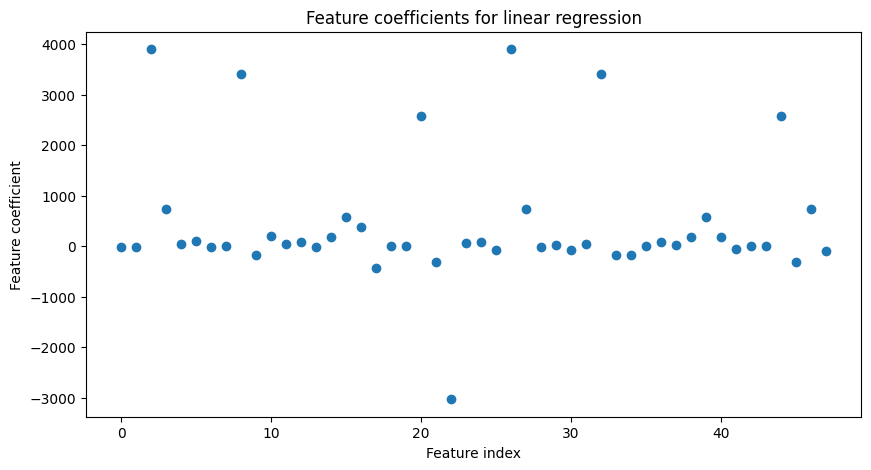

In [23]:
# Plot the coefficients
plt.figure(figsize=(10, 5))
plt.plot(reg.coef_[block_idx], 'o')
plt.xlabel('Feature index')
plt.ylabel('Feature coefficient')
plt.title('Feature coefficients for linear regression')
plt.show()

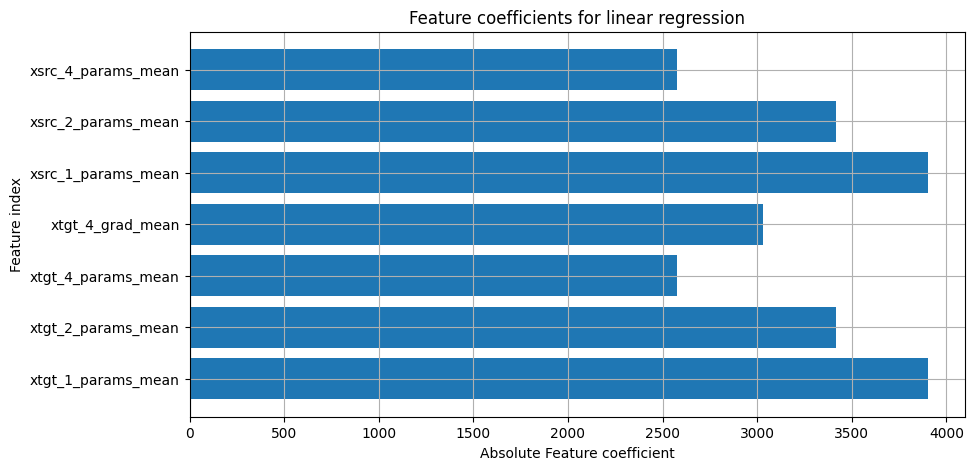

In [24]:
coeff = reg.coef_[block_idx]
imp_flag = np.abs(coeff) > np.abs(coeff).mean() + np.abs(coeff).std()
imp_coeff = np.abs(coeff[imp_flag])
imp_feats = df_x_train.columns[imp_flag]

# Plot the imp coefficients
plt.figure(figsize=(10, 5))
plt.barh(imp_feats, imp_coeff)
plt.ylabel('Feature index')
plt.xlabel('Absolute Feature coefficient')
plt.title('Feature coefficients for linear regression')
plt.grid()
# plt.xticks(rotation=90)
plt.show()

In [25]:
df_x_train.columns

Index(['xtgt_1_out_mean', 'xtgt_1_out_std', 'xtgt_1_params_mean',
       'xtgt_1_params_std', 'xtgt_1_grad_mean', 'xtgt_1_grad_std',
       'xtgt_2_out_mean', 'xtgt_2_out_std', 'xtgt_2_params_mean',
       'xtgt_2_params_std', 'xtgt_2_grad_mean', 'xtgt_2_grad_std',
       'xtgt_3_out_mean', 'xtgt_3_out_std', 'xtgt_3_params_mean',
       'xtgt_3_params_std', 'xtgt_3_grad_mean', 'xtgt_3_grad_std',
       'xtgt_4_out_mean', 'xtgt_4_out_std', 'xtgt_4_params_mean',
       'xtgt_4_params_std', 'xtgt_4_grad_mean', 'xtgt_4_grad_std',
       'xsrc_1_out_mean', 'xsrc_1_out_std', 'xsrc_1_params_mean',
       'xsrc_1_params_std', 'xsrc_1_grad_mean', 'xsrc_1_grad_std',
       'xsrc_2_out_mean', 'xsrc_2_out_std', 'xsrc_2_params_mean',
       'xsrc_2_params_std', 'xsrc_2_grad_mean', 'xsrc_2_grad_std',
       'xsrc_3_out_mean', 'xsrc_3_out_std', 'xsrc_3_params_mean',
       'xsrc_3_params_std', 'xsrc_3_grad_mean', 'xsrc_3_grad_std',
       'xsrc_4_out_mean', 'xsrc_4_out_std', 'xsrc_4_params_mean',
   

In [26]:
# err_valid_dict.update({"linear": mean_squared_error(df_y_valid, reg.predict(df_x_valid))})
# err_test_dict.update({"linear": mean_squared_error(df_y_test, reg.predict(df_x_test))})

In [27]:
reg.predict(df_x_test).argsort(axis=1)

array([[0, 1, 2, 3],
       [2, 1, 0, 3],
       [2, 1, 0, 3],
       [3, 2, 0, 1],
       [1, 0, 2, 3]])

In [28]:
df_y_test.values.argsort(axis=1)

array([[3, 2, 1, 0],
       [3, 2, 0, 1],
       [3, 2, 0, 1],
       [3, 0, 2, 1],
       [0, 1, 3, 2]])

In [29]:
reg.predict(df_x_valid).argsort(axis=1)

array([[2, 1, 0, 3],
       [0, 2, 1, 3],
       [3, 2, 0, 1],
       [1, 2, 0, 3],
       [2, 1, 0, 3]])

In [30]:
df_y_valid.values.argsort(axis=1)

array([[2, 3, 1, 0],
       [1, 2, 0, 3],
       [3, 0, 1, 2],
       [3, 1, 0, 2],
       [3, 2, 0, 1]])

In [31]:
df_y_valid

,yshap_1,yshap_2,yshap_3,yshap_4
36,-0.009875,-0.025051,-0.100816,-0.098933
23,0.000507,-0.000521,-0.000043,0.002371
26,-0.000724,-0.000025,0.000424,-0.000724
44,0.006868,0.004911,0.010305,0.003098
3,-0.013258,0.036912,-0.048632,-0.146692


Train Lasso

In [32]:
# alpha = 1e-3
# alpha = 1e-6
alpha = 1e-5
reg = Lasso(alpha=alpha).fit(df_x_train, df_y_train)

/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/linear_model/_coordinate_descent.py:648: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.902e-06, tolerance: 8.178e-07
  model = cd_fast.enet_coordinate_descent(
/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/linear_model/_coordinate_descent.py:648: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.283e-05, tolerance: 2.206e-06
  model = cd_fast.enet_coordinate_descent(
/home-local2/sasah14.extra.nobkp/envs/ttdg/lib/python3.8/site-packages/sklearn/linear_model/_coordinate_descent.py:648: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of 

In [33]:
mean_squared_error(df_y_train, reg.predict(df_x_train)), reg.score(df_x_train, df_y_train)

(0.0004085925712037067, 0.2983062161553789)

In [34]:
mean_squared_error(df_y_valid, reg.predict(df_x_valid)), reg.score(df_x_valid, df_y_valid)

(0.0015528802079428227, 0.05963860417692374)

In [35]:
mean_squared_error(df_y_test, reg.predict(df_x_test)), reg.score(df_x_test, df_y_test)

(0.00018278644464971483, 0.061499843049123426)

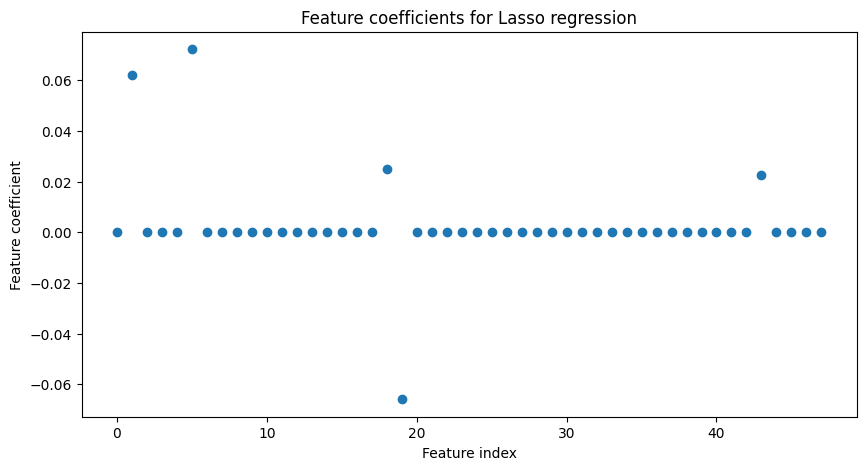

In [36]:
# Plot the coefficients
plt.figure(figsize=(10, 5))
plt.plot(reg.coef_[block_idx], 'o')
plt.xlabel('Feature index')
plt.ylabel('Feature coefficient')
plt.title('Feature coefficients for Lasso regression')
plt.show()

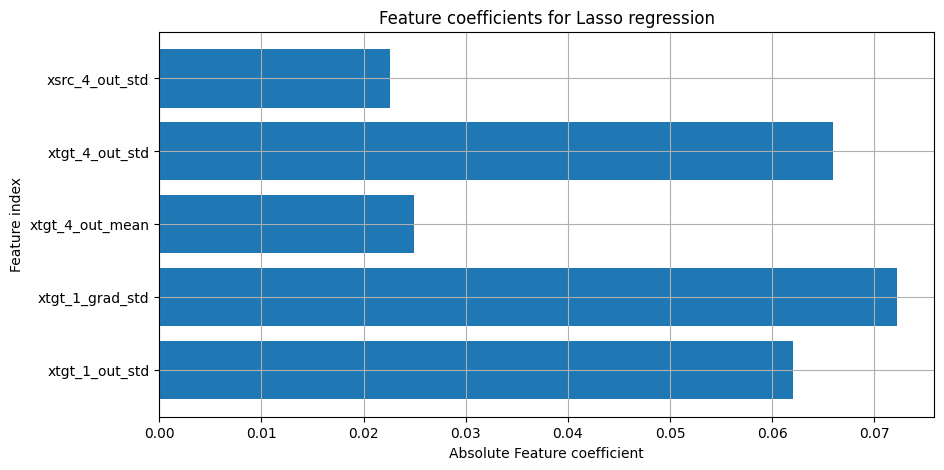

In [37]:
coeff = reg.coef_[block_idx]
imp_flag = np.abs(coeff) > np.abs(coeff).mean() + np.abs(coeff).std()
imp_coeff = np.abs(coeff[imp_flag])
imp_feats = df_x_train.columns[imp_flag]

# Plot the impcoefficients
plt.figure(figsize=(10, 5))
plt.barh(imp_feats, imp_coeff)
plt.ylabel('Feature index')
plt.xlabel('Absolute Feature coefficient')
plt.title('Feature coefficients for Lasso regression')
plt.grid()
# plt.xticks(rotation=90)
plt.show()

In [38]:
err_valid_dict.update({"lasso": mean_squared_error(df_y_valid, reg.predict(df_x_valid))})
err_test_dict.update({"lasso": mean_squared_error(df_y_test, reg.predict(df_x_test))})

Train Ridge

In [39]:
reg = Ridge(alpha=1e-4).fit(df_x_train, df_y_train)

In [40]:
mean_squared_error(df_y_train, reg.predict(df_x_train)), reg.score(df_x_train, df_y_train)

(0.0003419450666223143, 0.4970324751839885)

In [41]:
mean_squared_error(df_y_valid, reg.predict(df_x_valid)), reg.score(df_x_valid, df_y_valid)

(0.0016001682014866524, 0.09664106983735019)

In [42]:
mean_squared_error(df_y_test, reg.predict(df_x_test)), reg.score(df_x_test, df_y_test)

(0.00016899569254266364, 0.18454072153559692)

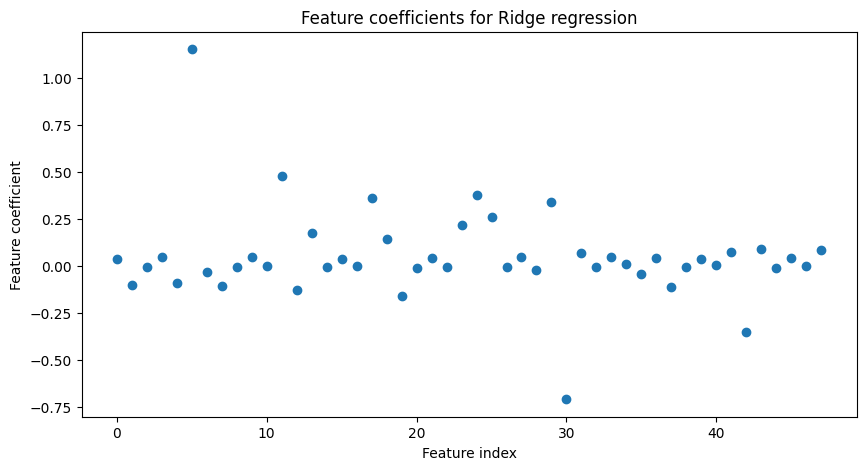

In [43]:
# Plot the coefficients
plt.figure(figsize=(10, 5))
plt.plot(reg.coef_[block_idx], 'o')
plt.xlabel('Feature index')
plt.ylabel('Feature coefficient')
plt.title('Feature coefficients for Ridge regression')
plt.show()

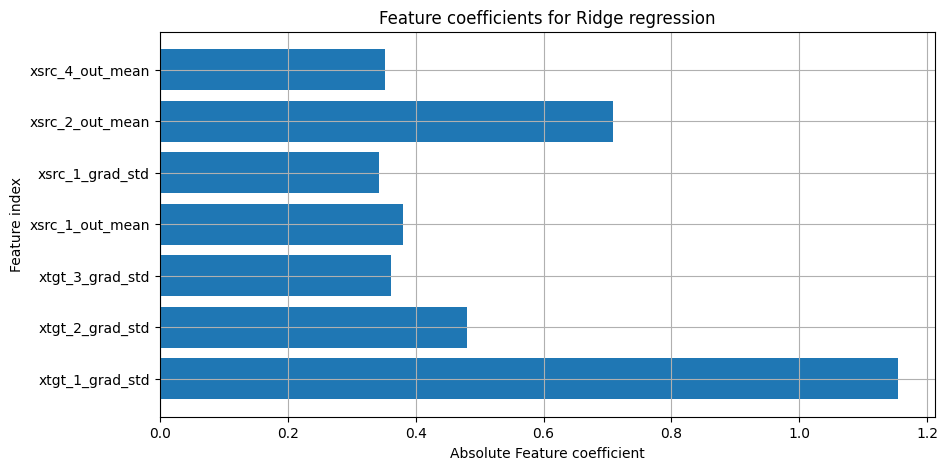

In [44]:
coeff = reg.coef_[block_idx]
imp_flag = np.abs(coeff) > np.abs(coeff).mean() + np.abs(coeff).std()
imp_coeff = np.abs(coeff[imp_flag])
imp_feats = df_x_train.columns[imp_flag]

# Plot the impcoefficients
plt.figure(figsize=(10, 5))
plt.barh(imp_feats, imp_coeff)
plt.ylabel('Feature index')
plt.xlabel('Absolute Feature coefficient')
plt.title('Feature coefficients for Ridge regression')
plt.grid()
# plt.xticks(rotation=90)
plt.show()

In [45]:
err_valid_dict.update({"ridge": mean_squared_error(df_y_valid, reg.predict(df_x_valid))})
err_test_dict.update({"ridge": mean_squared_error(df_y_test, reg.predict(df_x_test))})

Train DT

In [46]:
reg = DecisionTreeRegressor().fit(df_x_train, df_y_train)
# reg = DecisionTreeRegressor(max_depth=2).fit(df_x_train, df_y_train)

In [47]:
mean_squared_error(df_y_train, reg.predict(df_x_train)), reg.score(df_x_train, df_y_train)

(0.0, 1.0)

In [48]:
mean_squared_error(df_y_valid, reg.predict(df_x_valid)), reg.score(df_x_valid, df_y_valid)

(0.0019665377697968083, -0.7456932993909267)

In [49]:
mean_squared_error(df_y_test, reg.predict(df_x_test)), reg.score(df_x_test, df_y_test)

(0.0002886142173037046, -0.25878120569519536)

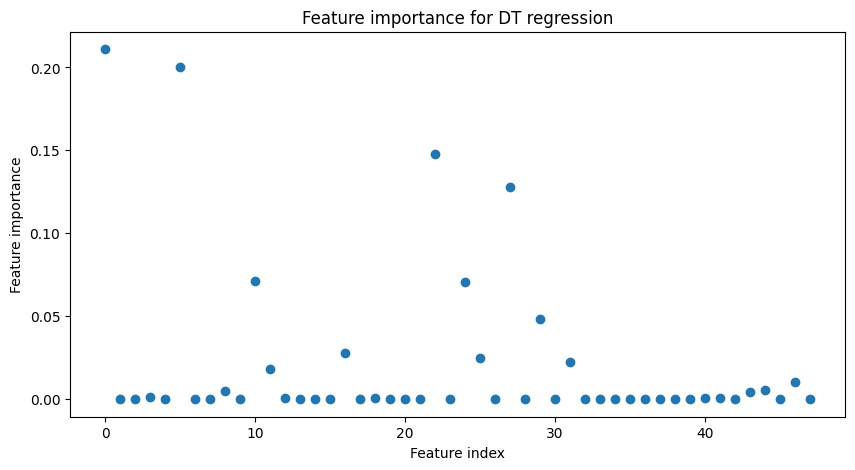

In [50]:
# Plot the coefficients
plt.figure(figsize=(10, 5))
plt.plot(reg.feature_importances_, 'o')
plt.xlabel('Feature index')
plt.ylabel('Feature importance')
plt.title('Feature importance for DT regression')
plt.show()

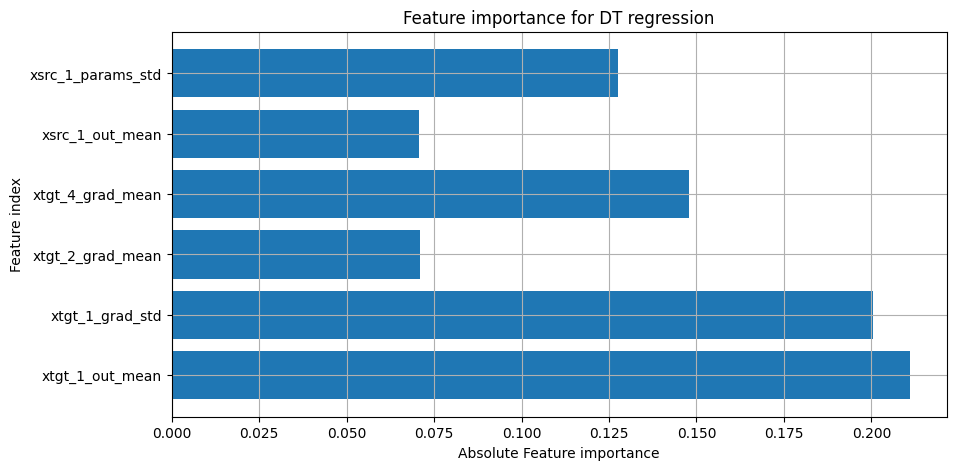

In [51]:
coeff = reg.feature_importances_
imp_flag = np.abs(coeff) > np.abs(coeff).mean() + np.abs(coeff).std()
# imp_flag = np.abs(coeff) > 0
imp_coeff = np.abs(coeff[imp_flag])
imp_feats = df_x_train.columns[imp_flag]

# Plot the impcoefficients
plt.figure(figsize=(10, 5))
plt.barh(imp_feats, imp_coeff)
plt.ylabel('Feature index')
plt.xlabel('Absolute Feature importance')
plt.title('Feature importance for DT regression')
plt.grid()
# plt.xticks(rotation=90)
plt.show()

In [52]:
err_valid_dict.update({"dt": mean_squared_error(df_y_valid, reg.predict(df_x_valid))})
err_test_dict.update({"dt": mean_squared_error(df_y_test, reg.predict(df_x_test))})

In [53]:
# reg.predict(df_x_test).argsort(axis=1)

In [54]:
# df_y_test.values.argsort(axis=1)

In [55]:
# reg.predict(df_x_valid).argsort(axis=1)

In [56]:
# df_y_valid.values.argsort(axis=1)

In [57]:
# df_y_valid

Train RF

In [58]:
reg = RandomForestRegressor().fit(df_x_train, df_y_train)

In [59]:
mean_squared_error(df_y_train, reg.predict(df_x_train)), reg.score(df_x_train, df_y_train)

(0.00010255897663569139, 0.8542506180312084)

In [60]:
mean_squared_error(df_y_valid, reg.predict(df_x_valid)), reg.score(df_x_valid, df_y_valid)

(0.0015288941021394734, -0.0078533689941101)

In [61]:
mean_squared_error(df_y_test, reg.predict(df_x_test)), reg.score(df_x_test, df_y_test)

(0.00043328894936198366, -0.9328649739436532)

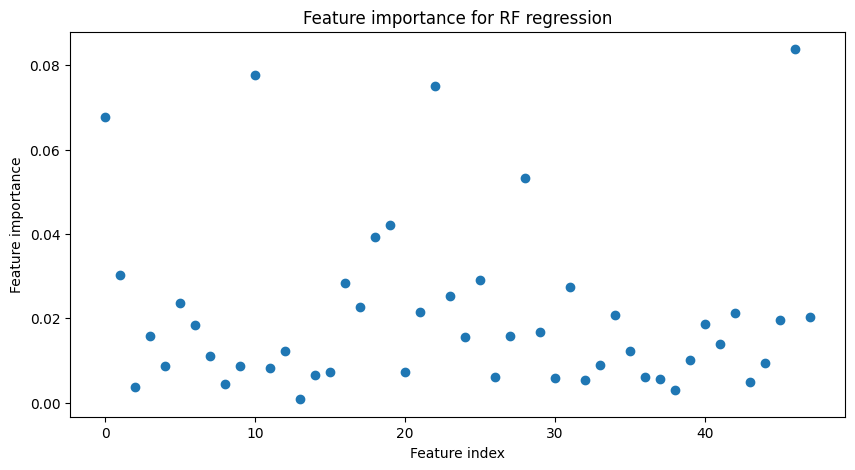

In [62]:
# Plot the coefficients
plt.figure(figsize=(10, 5))
plt.plot(reg.feature_importances_, 'o')
plt.xlabel('Feature index')
plt.ylabel('Feature importance')
plt.title('Feature importance for RF regression')
plt.show()

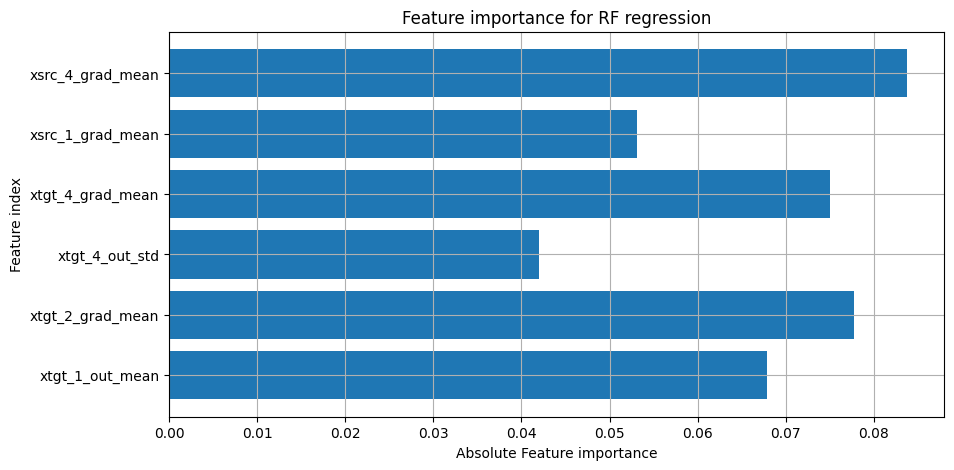

In [63]:
coeff = reg.feature_importances_
imp_flag = np.abs(coeff) > np.abs(coeff).mean() + np.abs(coeff).std()
imp_coeff = np.abs(coeff[imp_flag])
imp_feats = df_x_train.columns[imp_flag]

# Plot the impcoefficients
plt.figure(figsize=(10, 5))
plt.barh(imp_feats, imp_coeff)
plt.ylabel('Feature index')
plt.xlabel('Absolute Feature importance')
plt.title('Feature importance for RF regression')
plt.grid()
# plt.xticks(rotation=90)
plt.show()

In [64]:
err_valid_dict.update({"rf": mean_squared_error(df_y_valid, reg.predict(df_x_valid))})
err_test_dict.update({"rf": mean_squared_error(df_y_test, reg.predict(df_x_test))})

In [65]:
# save reg regressor to file
if save_rf_meta_model:
    with open('../../rf_src_meanstd_block.pkl', 'wb') as f:
        pickle.dump(reg, f)

Train Gradient boosting

## Analysis

<Axes: title={'center': 'Validation Error'}>

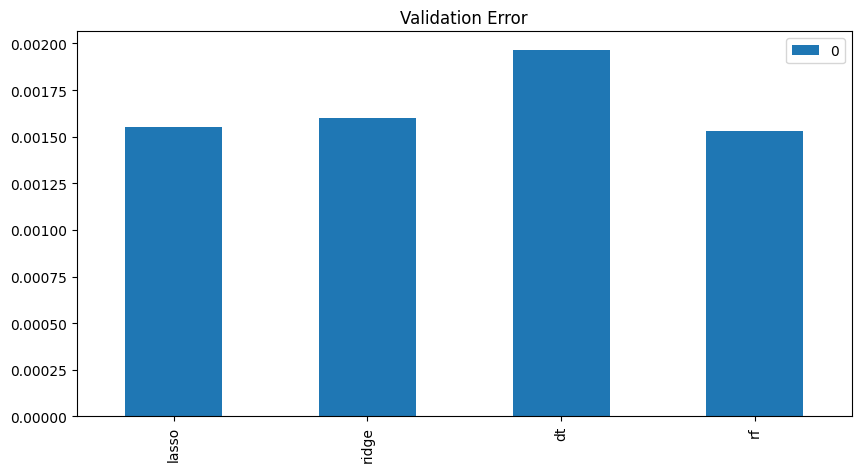

In [66]:
pd.DataFrame.from_dict(err_valid_dict, orient='index').plot(kind='bar', figsize=(10, 5), title='Validation Error')

<Axes: title={'center': 'Test Error'}>

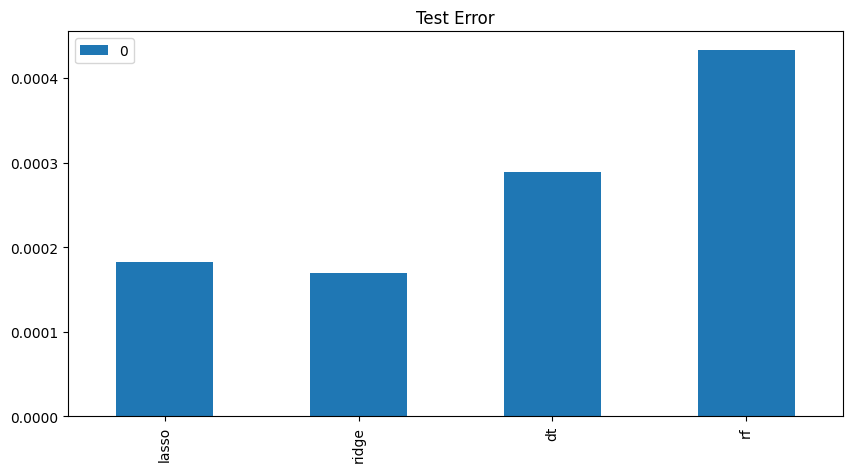

In [67]:
pd.DataFrame.from_dict(err_test_dict, orient='index').plot(kind='bar', figsize=(10, 5), title='Test Error')